In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from matplotlib.colors import to_rgba
from appa2.grid import Icosphere, latlon_to_xyz, PolarCapFilter
import math
from typing import Optional





In [2]:

def plot_icospheres(levels=(0, 1, 2), polar_cap_filter = None, elev=30, azim=-60, show_poles=True):
    fig = plt.figure(figsize=(5 * len(levels), 5))

    for panel, level in enumerate(levels, start=1):
        sphere = Icosphere(level)
        vertices, edges = sphere.get_graph(polar_cap_filter=polar_cap_filter)
        xyz = latlon_to_xyz(vertices).cpu().numpy()
        edges = edges.cpu().numpy()
        edges = np.unique(np.sort(edges, axis=1), axis=0)
        edges = edges[edges[:, 0] != edges[:, 1]]

        # Angular separation between connected vertices on the unit sphere.
        a, b = xyz[edges[:, 0]], xyz[edges[:, 1]]
        angles = np.arctan2(
            np.linalg.norm(np.cross(a, b), axis=1),
            np.sum(a * b, axis=1),
        )
        finest_km = angles.min() * 6371.0

        
        ax = fig.add_subplot(1, len(levels), panel, projection="3d")
        ax.view_init(elev=elev, azim=azim)


        el, az = np.radians([elev, azim])
        view_direction = np.array([
            np.cos(el) * np.cos(az),
            np.cos(el) * np.sin(az),
            np.sin(el),
        ])

        front = xyz @ view_direction >= 0

        colors = np.tile(to_rgba("tab:blue"), (len(xyz), 1))
        colors[:, 3] = np.where(front, 1.0, 0.15)

        ax.add_collection3d(
            Line3DCollection(xyz[edges], colors="gray", linewidths=0.5)
        )
        
        ax.scatter(*xyz.T, s=8, c=colors, depthshade=False)
        ax.set(xlim=(-1, 1), ylim=(-1, 1), zlim=(-1, 1),
            title = f"Subdivision {level}: {len(vertices)} vertices\n"
            f"Minimum spacing: {finest_km:.2f} km"
        )
        ax.set_box_aspect((1, 1, 1))
        ax.set_axis_off()

        if show_poles:
            ax.scatter(
                [0, 0], [0, 0], [1, -1],
                marker="*", s=100, color="red",
                depthshade=False, label="Poles",
            )
            ax.text(0, 0, 1.1, "N", ha="center", color="red")
            ax.text(0, 0, -1.1, "S", ha="center", color="red")

            if polar_cap_filter is not None:
                latitudes = np.linspace(-np.pi / 2, np.pi / 2, 361)

                for longitude in polar_cap_filter.longitudes:
                    lon = np.radians(longitude)

                    xyz_line = np.column_stack([
                        np.cos(latitudes) * np.cos(lon),
                        np.cos(latitudes) * np.sin(lon),
                        np.sin(latitudes),
                    ])

                    front_line = xyz_line @ view_direction >= 0

                    for visible, linestyle, alpha in [
                        (front_line, "-", 1.0),
                        (~front_line, ":", 0.25),
                    ]:
                        # NaNs break the line across hidden portions.
                        points = np.where(
                            visible[:, None], xyz_line, np.nan
                        )
                        ax.plot(
                            *points.T,
                            color="red",
                            linestyle=linestyle,
                            linewidth=1.0,
                            alpha=alpha,
                        )

    plt.tight_layout()
    plt.show()


def resolution(level, return_influence_radius_per_edge=False):
    sphere = Icosphere(level)
    vertices, edges = sphere.get_graph()
    xyz = latlon_to_xyz(vertices).cpu().numpy()
    edges = edges.cpu().numpy()
    edges = np.unique(np.sort(edges, axis=1), axis=0)
    edges = edges[edges[:, 0] != edges[:, 1]]

    # Angular separation between connected vertices on the unit sphere.
    a, b = xyz[edges[:, 0]], xyz[edges[:, 1]]
    angles = np.arctan2(
        np.linalg.norm(np.cross(a, b), axis=1),
        np.sum(a * b, axis=1),
    )
    finest_km = angles.min() * 6371.0
    if return_influence_radius_per_edge:
        influence_radius_per_edge = 6371.0 * 2 * math.asin(math.sqrt(1 / vertices.shape[0]))
        return finest_km, influence_radius_per_edge
    return finest_km




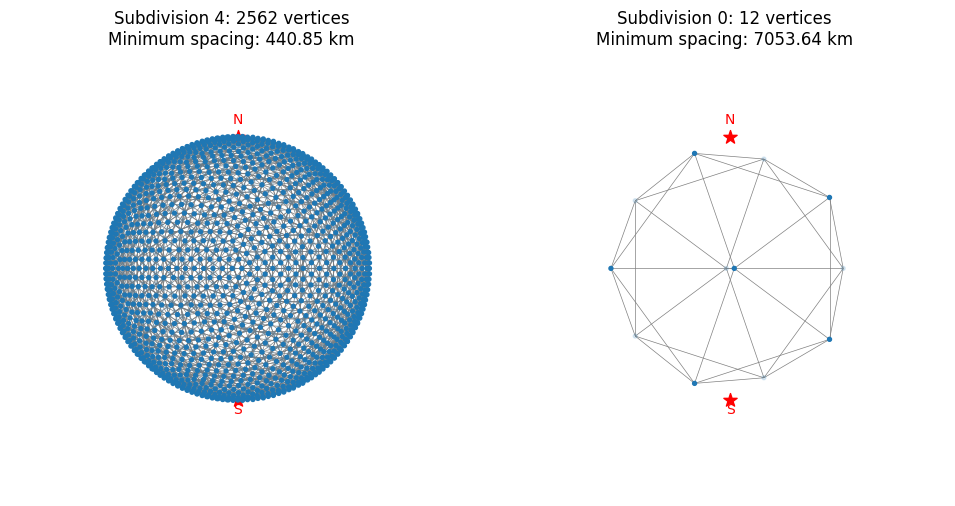

In [3]:
plot_icospheres((4,0), elev=0)

In [26]:
riops_filter = PolarCapFilter(
    longitude_bands=[-100, 100],
    min_latitudes=[25, 43],
)


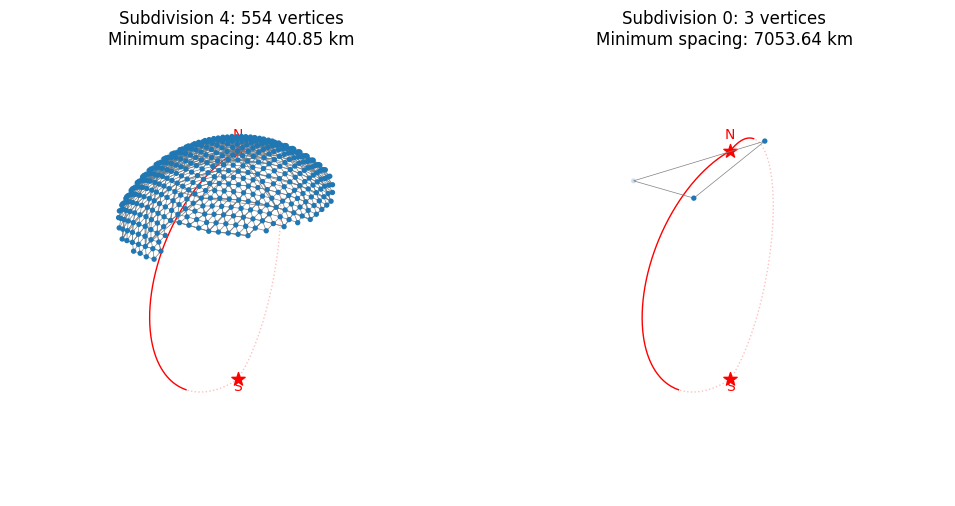

In [29]:
plot_icospheres((4,0), polar_cap_filter=riops_filter, elev=30)

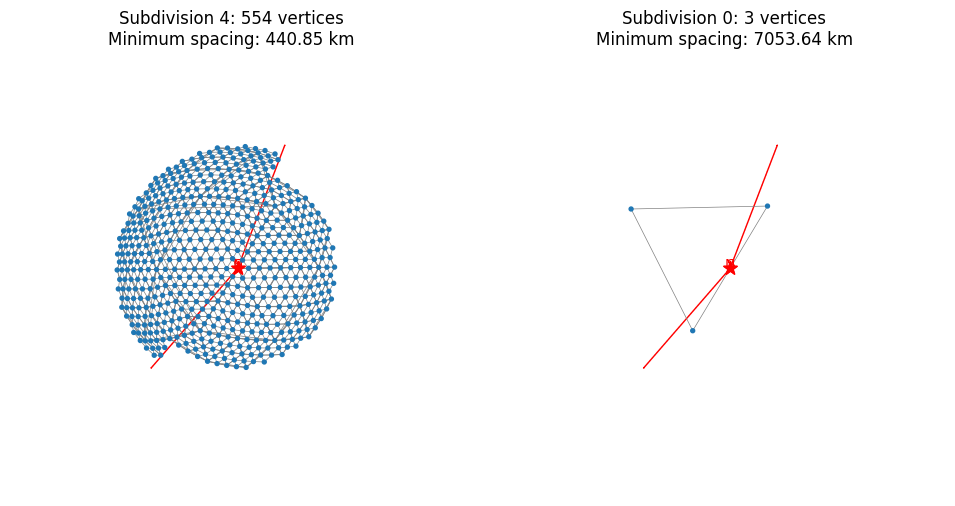

In [30]:
plot_icospheres((4,0), polar_cap_filter=riops_filter, elev=90)

In [8]:
riops_filter = PolarCapFilter(
    longitude_bands=[-123, -59, 50, 130],
    min_latitudes=[50, 25, 70, 43],
)


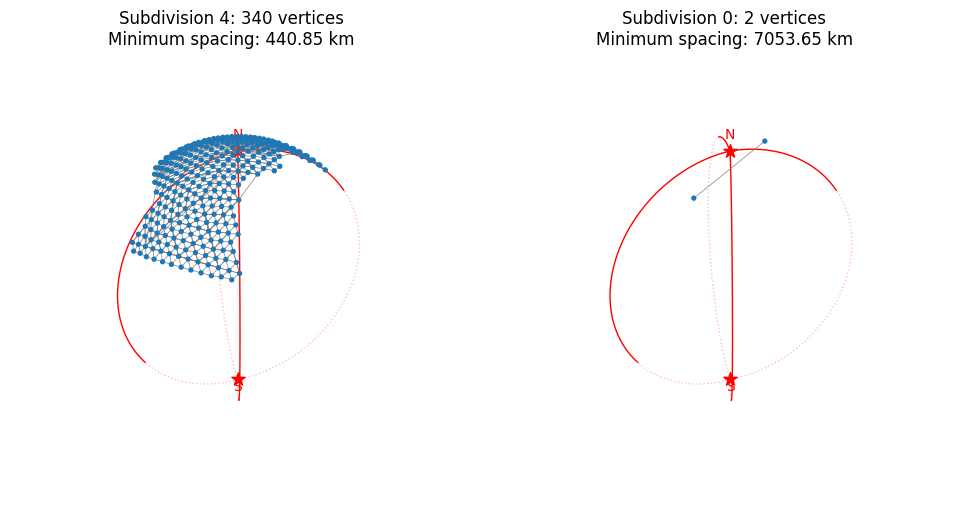

In [9]:
plot_icospheres((4,0), polar_cap_filter=riops_filter, elev=30)

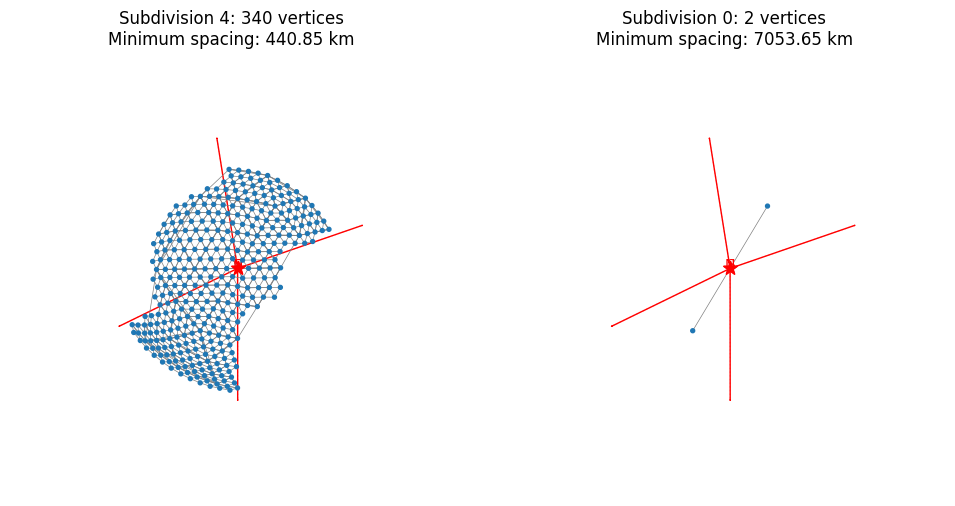

In [10]:
plot_icospheres((4,0), polar_cap_filter=riops_filter, elev=90)

# Data

In [3]:
import xarray as xr
import glob

/lus/scratch/PGooya/pixi/envs/appa2-5641269332989513266/envs/gpu-dev-castner/lib/python3.11/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.4.0' currently installed).
  from pandas.core import (


In [4]:
glorys_path = "/lus/scratch/PGooya/data/glorys_daily"
files = sorted(glob.glob(f"{glorys_path}/*.nc"))

In [5]:
ds = xr.open_dataset(files[0])

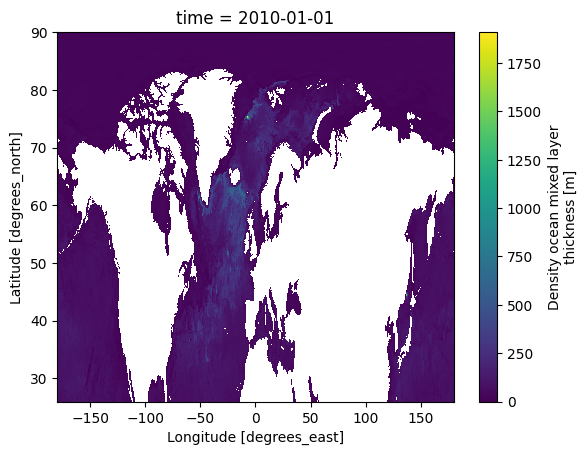

In [8]:
ds.mlotst[0].plot()

In [13]:
lon = ds.longitude
min_lat = xr.where((lon >= -100) & (lon <= 100), 25, 43)
mask = ds.latitude >= min_lat
ds_masked = ds.where(mask)

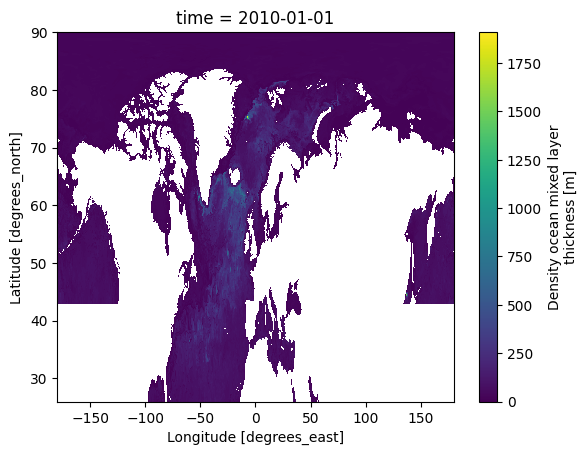

In [14]:
ds_masked.mlotst[0].plot()


In [6]:
import torch
from torch import Tensor

# from appa2.grid import create_glorys, create_original_grid, GLORYS_MIN_LAT, SUPPORTED_GRIDS, POLAR_GRIDS

In [7]:
SUPPORTED_GRIDS = ["N_320", "glorys", "RIOPS"]
POLAR_GRIDS = ["RIOPS"]
GLORYS_MIN_LAT= 26

In [50]:


def create_glorys(min_lat: float = GLORYS_MIN_LAT) -> Tensor:
    """Create GLORYS vertices ordered by ascending latitude."""
    if not -80 <= min_lat <= 90:
        raise ValueError("min_lat must be between -80 and 90 degrees.")

    lat = -80 + torch.arange(2041, dtype=torch.float64) / 12
    lat = lat[lat >= min_lat]
    lon = -180 + torch.arange(4320, dtype=torch.float64) / 12

    return torch.cartesian_prod(lat, lon).float()

    
def create_original_grid(
        grid_name: SUPPORTED_GRIDS,
        polar_cap_filter: Optional[PolarCapFilter] = None,
    ) -> Tensor:

        if grid_name == "N_320":
            coord = create_N320()
        elif grid_name == "glorys":
            coord = create_glorys(GLORYS_MIN_LAT)
        elif grid_name == "RIOPS":
            coord = create_ORG(80)
        else:
            raise ValueError(
                f"Unsupported grid {grid_name}. Supported grids are 'N_320', 'glorys', 'RIOPS'."
            )

        if polar_cap_filter is not None:
            mask = polar_cap_filter(coord)
            coord = coord[mask]

        return coord, mask

In [51]:
coords = create_glorys(26)

In [48]:
coords_from_glorys = ds.stack(coordinates = ["latitude", "longitude"]).coordinates.values
lats = torch.from_numpy(np.array([coord[0] for coord in coords_from_glorys]))
lons = torch.from_numpy(np.array([coord[1] for coord in coords_from_glorys]))

coords_from_glorys = torch.stack((lats, lons), dim=1).float()

In [52]:
coords

tensor([[  26.0000, -180.0000],
        [  26.0000, -179.9167],
        [  26.0000, -179.8333],
        ...,
        [  90.0000,  179.7500],
        [  90.0000,  179.8333],
        [  90.0000,  179.9167]])

In [53]:
coords_from_glorys

tensor([[  26.0000, -180.0000],
        [  26.0000, -179.9167],
        [  26.0000, -179.8333],
        ...,
        [  90.0000,  179.7500],
        [  90.0000,  179.8333],
        [  90.0000,  179.9167]])

In [ ]:
coords_from_glorys == coords

tensor(True)

In [ ]:
riops_filter = PolarCapFilter(
    longitude_bands=[-100, 100],
    min_latitudes=[25, 43],
)

coords, mask = create_original_grid("glorys", polar_cap_filter=riops_filter)